In [ ]:
import numpyro
import pandas as pd
import jax.numpy as jnp
import jax

def process_jhu_covid_csv(file_name):
    df = pd.read_csv(file_name, index_col='FIPS')
    df = df.loc[:, '1/22/20':'3/9/23'].sort_index().loc[1001:56045, :].transpose()
    df.columns = pd.Index(pd.Index(df.columns, dtype='int64'), dtype='str').str.pad(5,fillchar='0')
    df.index = pd.to_datetime(df.index, format="%m/%d/%y")
    return df

In [ ]:
confirmed = process_jhu_covid_csv('raw_data/time_series_covid19_confirmed_US.csv')

from epymorph.kit import *

contiguous = ['AL',# 'AK',
              'AZ','AR','CA','CO','CT','DE','FL','GA',# 'HI',
              'ID','IL','IN','IA','KS','KY','LA','ME','MD',
              'MA','MI','MN','MS','MO','MT','NE','NV','NH',
              'NJ','NM','NY','NC','ND','OH','OK','OR','PA',
              'RI','SC','SD','TN','TX','UT','VT','VA','WA',
              'WV','WI','WY']

scope = CountyScope.in_states(contiguous, year=2020)

In [3]:
from epymorph.adrio.acs5 import Population
from epymorph.adrio.us_tiger import GeometricCentroid

populations =Population().with_context(scope=scope).evaluate()
centroids = GeometricCentroid().with_context(scope=scope).evaluate()

In [4]:
knots = pd.read_csv("raw_data/knots100.csv", header=None, names=["Longitude", "Latitude"])
x_knots = jnp.concatenate((knots["Longitude"].to_numpy()[:, None], knots["Latitude"].to_numpy()[:, None]), axis=1)
n_knots = x_knots.shape[0]

In [5]:
import numpy as np

rng = np.random.default_rng(0)
train_idx = rng.choice(len(scope.node_ids), round(0.75*len(scope.node_ids)), replace=False)

In [6]:
train_idx.sort()

In [7]:
full_idx = np.arange(0, len(scope.node_ids))
test_idx = full_idx[~np.isin(full_idx, train_idx)]


In [ ]:
x_sample = jnp.stack((centroids['longitude'], centroids['latitude']), axis=1)
n_knots = x_knots.shape[0]

In [11]:
from sklearn.metrics.pairwise import haversine_distances

x_knots_latlon_rads = jnp.flip(x_knots, axis=1)*2*jnp.pi/360
x_sample_latlon_rads = jnp.flip(x_sample, axis=1)*2*jnp.pi/360
earth_radius_km = 6371

knots_dist = haversine_distances(x_knots_latlon_rads, x_knots_latlon_rads)*earth_radius_km
rect_dist = haversine_distances(x_sample_latlon_rads, x_knots_latlon_rads)*earth_radius_km

In [12]:
def kernel(distance, variance, length):
    k = variance * jnp.exp(-distance / (2*length))
    return k

variance = 1**2
phi = 0.005
length_scale = 1/(2*phi)
K_knots = variance * jnp.exp(-knots_dist/(2*length_scale))
K_rect = variance * jnp.exp(-rect_dist/(2*length_scale))
mu_knots = jnp.zeros(n_knots)
Kinv = jnp.linalg.inv(K_knots)

In [14]:
L = jnp.linalg.cholesky(K_knots)

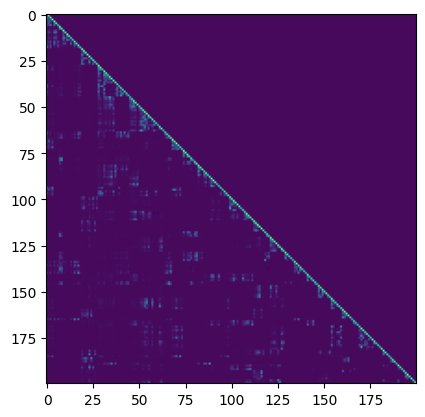

In [15]:
import matplotlib.pyplot as plt

plt.imshow(L)

In [16]:
import matplotlib.pyplot as plt

shift = 3*7
C = confirmed[scope.node_ids]
G = (C.iloc[shift:, :] - C.iloc[:-shift, :].to_numpy())/populations[jnp.newaxis, :]*100_000
skip = 7
prevalence = G.iloc[::7, :].clip(lower=0, upper=None)

power = 0.2


In [17]:
covariates = pd.read_csv("raw_data/covariates.csv", index_col='fips')
covariates.index = pd.Index(covariates.index, dtype='str').str.pad(5,fillchar='0')
covariates = covariates.loc[scope.node_ids]

In [18]:
def standardize_data(df):
    return 

In [19]:
def standardize(x):
    return (x - x.mean())/x.std()

In [ ]:
Rural1 = covariates['Rural']
Urban1 = 1 - Rural1

Black = standardize(100*covariates['black']/covariates['tot_pop'])
BlackR = Black*Rural1
BlackU = Black*Urban1

Age25 = standardize(100*covariates['age25_49']/covariates['tot_pop'])
Age25R = Age25*Rural1
Age25U = Age25*Urban1

Smokers = standardize(covariates['Smokers'])
SmokersR = Smokers*Rural1
SmokersU = Smokers*Urban1

Diabetes = standardize(covariates['Diabetic'])

DiabetesR = Diabetes*Rural1
DiabetesU = Diabetes*Urban1

Obesity = standardize(covariates['pctobesity'])
ObesityR = Obesity*Rural1
ObesityU = Obesity*Urban1

Association = standardize(covariates['associationrate'])
AssociationR = Association*Rural1
AssociationU = Association*Urban1

PCP = standardize(covariates['PCP'])
PCPR = PCP*Rural1
PCPU = PCP*Urban1

ICU = standardize(100000*covariates['icubeds']/covariates['tot_pop'])
ICUR = ICU*Rural1
ICUU = ICU*Urban1

Hospital = standardize(covariates['hospcount'])
HospitalR = Hospital*Rural1
HospitalU = Hospital*Urban1

LHS = standardize(covariates['lesshighschool'])
LHSR = LHS*Rural1
LHSU = LHS*Urban1

Poverty = standardize(100*covariates['povertycounts']/covariates['tot_pop'])
PovertyR = Poverty*Rural1
PovertyU = Poverty*Urban1

FairPoor = standardize(covariates[' FairPoor Health'])
FairPoorR = FairPoor*Rural1
FairPoorU = FairPoor*Urban1

Rural = Rural1

Metro1 = covariates['tot_pop'] >= 500000
Metro = Metro1.astype(float)

data = pd.DataFrame({"Rural":Rural, "Black": Black, "BlackR":BlackR, "Age25":Age25,
                     "Age25R":Age25R, "Smokers":Smokers, "SmokersR":SmokersR, 
                     "Diabetes":Diabetes, "DiabetesR":DiabetesR,
                     "Obesity":Obesity, "ObesityR":ObesityR,  "ICU":ICU, "PCP":PCP, "Hospital":Hospital})

In [ ]:
import numpyro.distributions as dist
dist.MultivariateNormal(jnp.broadcast_to(0, (1000,n_knots)), scale_tril=L)

<numpyro.distributions.continuous.MultivariateNormal object at 0x14815440ad0 with batch shape (1000,) and event shape (200,)>

In [22]:
A = K_rect@Kinv
A_train = K_rect[train_idx, :]@Kinv
A_test = K_rect[test_idx, :]@Kinv


In [23]:
import numpyro.distributions as dist
from numpyro.contrib.control_flow import scan

def regression_model(X, y, A):
    beta = numpyro.sample("beta", dist.Normal(jnp.zeros(X.shape[1]), 1))
    intercept = numpyro.sample("intercept", dist.Normal(0, 1))
    sigma_obs = numpyro.sample("sigma_obs", dist.HalfNormal(1))
    mu = numpyro.deterministic("mu", intercept + X@beta)
    numpyro.sample("obs", dist.Normal(jnp.broadcast_to(mu.reshape((-1, 1)), y.shape), sigma_obs), obs=y)

In [ ]:
def regression_model(X, y, A):
    beta = numpyro.sample("beta", dist.Normal(jnp.zeros(X.shape[1]), 1))
    intercept = numpyro.sample("intercept", dist.Normal(0, 1))
    sigma_obs = numpyro.sample("sigma_obs", dist.HalfNormal(1))
    mu = numpyro.deterministic("mu", intercept + X@beta)

    sigma_eta = numpyro.sample("sigma_eta", dist.HalfNormal(1))

    eta_temp = numpyro.sample("eta_temp", dist.Normal(jnp.broadcast_to(0, (n_knots, y.shape[1])), sigma_eta))
    eta = L@eta_temp

    rho = 0.9
    def transition(carry, t):
        m_t = rho*carry
        w_t = m_t + eta[:, t]
        return w_t, w_t

    timesteps = jnp.arange(y.shape[1])
    init = jnp.zeros(n_knots)
    _, w_temp = scan(transition, init, timesteps)

    spt_effect = A@w_temp.T

    filtered = numpyro.deterministic("filtered", jnp.broadcast_to(mu.reshape((-1, 1)), y.shape) + spt_effect)

    numpyro.sample("obs", dist.Normal(filtered, sigma_obs), obs=y)

In [27]:
y = standardize((prevalence**power).to_numpy().T)
y_train = y[train_idx, :]
y_test = y[test_idx, :]

In [28]:
X = data.to_numpy()
X_train = X[train_idx, :]
X_test = X[test_idx, :]

In [29]:
rng_key = jax.random.PRNGKey(0)

In [ ]:
n_weeks = y.shape[0]
n_nodes = y.shape[1]

t = jnp.arange(0, n_weeks)

sampler = numpyro.infer.NUTS(regression_model)

mcmc = numpyro.infer.MCMC(
    sampler,
    num_warmup=1000,
    num_samples=1000,
    num_chains=1,
    progress_bar=True
)
mcmc.run(rng_key, X=X_train, y=y_train, A=A_train)
mcmc.print_summary()
samples = mcmc.get_samples()

sample: 100%|██████████| 2000/2000 [49:50<00:00,  1.50s/it, 255 steps of size 1.62e-02. acc. prob=0.86]  



                       mean       std    median      5.0%     95.0%     n_eff     r_hat
          beta[0]     -0.07      0.00     -0.07     -0.07     -0.07   1532.72      1.00
          beta[1]     -0.02      0.00     -0.02     -0.03     -0.02   1783.94      1.00
          beta[2]      0.00      0.00      0.00     -0.00      0.00   1933.04      1.00
          beta[3]      0.02      0.00      0.02      0.01      0.02   2033.96      1.00
          beta[4]      0.03      0.00      0.03      0.03      0.03   2009.03      1.00
          beta[5]      0.05      0.00      0.05      0.04      0.05   1939.37      1.00
          beta[6]      0.01      0.00      0.01      0.01      0.01   2378.26      1.00
          beta[7]     -0.03      0.00     -0.03     -0.03     -0.02   1577.22      1.00
          beta[8]      0.02      0.00      0.02      0.02      0.03   1953.39      1.00
          beta[9]      0.02      0.00      0.02      0.02      0.03   2509.12      1.00
         beta[10]      0.01    

In [37]:
import pickle

with open('temp.pkl', 'wb') as f:
    pickle.dump(samples, f)

In [ ]:
with open('temp.pkl', 'rb') as f:
    loaded_samples = pickle.load(f)

In [40]:
loaded_samples["mu"] = loaded_samples["mu"].mean(axis=1)

In [46]:
rng_key, rng_key_ = jax.random.split(rng_key)
predictive = numpyro.infer.Predictive(regression_model, loaded_samples)
predictions = predictive(rng_key_, X=X_test, y=y_test, A=A_test)


In [ ]:
list(enumerate(scope.labels[test_idx]))

[(0, 'Bibb, AL'),
 (1, 'Choctaw, AL'),
 (2, 'Dale, AL'),
 (3, 'DeKalb, AL'),
 (4, 'Franklin, AL'),
 (5, 'Henry, AL'),
 (6, 'Lawrence, AL'),
 (7, 'Marengo, AL'),
 (8, 'Marshall, AL'),
 (9, 'Mobile, AL'),
 (10, 'Montgomery, AL'),
 (11, 'Pickens, AL'),
 (12, 'Russell, AL'),
 (13, 'St. Clair, AL'),
 (14, 'Talladega, AL'),
 (15, 'Coconino, AZ'),
 (16, 'Yavapai, AZ'),
 (17, 'Baxter, AR'),
 (18, 'Chicot, AR'),
 (19, 'Cleveland, AR'),
 (20, 'Columbia, AR'),
 (21, 'Craighead, AR'),
 (22, 'Crittenden, AR'),
 (23, 'Hot Spring, AR'),
 (24, 'Johnson, AR'),
 (25, 'Lawrence, AR'),
 (26, 'Lincoln, AR'),
 (27, 'Lonoke, AR'),
 (28, 'Montgomery, AR'),
 (29, 'Nevada, AR'),
 (30, 'Newton, AR'),
 (31, 'Perry, AR'),
 (32, 'Pulaski, AR'),
 (33, 'St. Francis, AR'),
 (34, 'Searcy, AR'),
 (35, 'Sharp, AR'),
 (36, 'Union, AR'),
 (37, 'Washington, AR'),
 (38, 'Yell, AR'),
 (39, 'Butte, CA'),
 (40, 'El Dorado, CA'),
 (41, 'Fresno, CA'),
 (42, 'Imperial, CA'),
 (43, 'Inyo, CA'),
 (44, 'Kern, CA'),
 (45, 'Kings, CA')

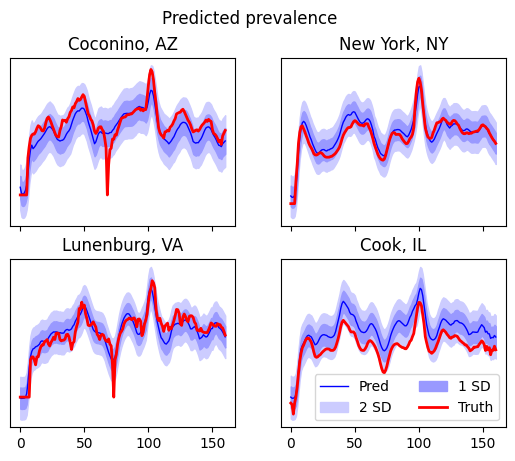

In [ ]:

nodes = [15, 450, 720, 153]
n_nodes = len(nodes)

fig, axs = plt.subplots(2, 2, sharex=True)
axs = np.ravel(axs)
for i in range(len(axs)):
    ax = axs[i]
    node = nodes[i]
    truth = predictions['obs'][0, node, :]
    t = np.arange(len(truth))
    mean_pred = predictions['filtered'][:, node, :].mean(axis=0)
    sd_pred = predictions['filtered'][:, node, :].std(axis=0)
    obs_err_mean = loaded_samples['sigma_obs'].mean()
    total_pred_sd = np.sqrt(sd_pred**2 + obs_err_mean**2)
    ax.plot(t, mean_pred, 'b', linewidth=1)
    ax.set_title('')
    ax.fill_between(t, mean_pred-2*total_pred_sd, mean_pred+2*total_pred_sd, color=[0.8, 0.8, 1])
    ax.fill_between(t, mean_pred-total_pred_sd, mean_pred+total_pred_sd, color=[0.6, 0.6, 1])
    ax.plot(t, truth, 'r', linewidth=2)
    ax.set_title(scope.labels[test_idx[node]])
    ax.set_yticks([])
axs[-1].legend(["Pred", "2 SD", "1 SD", "Truth"], ncol=2)
fig.suptitle('Predicted prevalence') 
plt.savefig('pred.png', bbox_inches='tight', dpi=300)

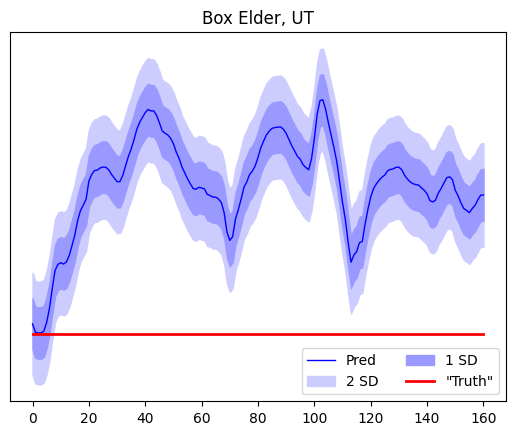

In [ ]:
node = 693

truth = predictions['obs'][0, node, :]
t = np.arange(len(truth))
mean_pred = predictions['filtered'][:, node, :].mean(axis=0)
sd_pred = predictions['filtered'][:, node, :].std(axis=0)
obs_err_mean = loaded_samples['sigma_obs'].mean()
total_pred_sd = np.sqrt(sd_pred**2 + obs_err_mean**2)
plt.plot(t, mean_pred, 'b', linewidth=1)

plt.fill_between(t, mean_pred-2*total_pred_sd, mean_pred+2*total_pred_sd, color=[0.8, 0.8, 1])
plt.fill_between(t, mean_pred-total_pred_sd, mean_pred+total_pred_sd, color=[0.6, 0.6, 1])
plt.plot(t, truth, 'r', linewidth=2)
plt.title(scope.labels[test_idx[node]])
plt.yticks([])
plt.legend(["Pred", "2 SD", "1 SD", "\"Truth\""], ncol=2)
plt.savefig('data_reporting.png', bbox_inches='tight', dpi=300)

In [ ]:
import scipy.stats

rmses = []
rmses_rural = []
rmses_urban = []
loglikes = []

for i_node in range(y_test.shape[0]):
    truth = predictions['obs'][0, i_node, :]
    mean_pred = predictions['filtered'][:, i_node, :].mean(axis=0)
    sd_pred = predictions['filtered'][:, i_node, :].std(axis=0)
    obs_err_mean = loaded_samples['sigma_obs'].mean()
    total_pred_sd = np.sqrt(sd_pred**2 + obs_err_mean**2)
    rmse = np.sqrt(((mean_pred - truth)**2).mean())
    rmses.append(rmse)

    if X_test[i_node, 0] == 1:
        rmses_rural.append(rmse)
    else:
        rmses_urban.append(rmse)

    loglike = scipy.stats.norm.logpdf(truth, loc=mean_pred, scale=obs_err_mean).mean()
    loglikes.append(loglike)




In [53]:
print(f"Average RMSE: {np.sqrt(np.power(rmses, 2).mean())}")
print(f"Average Log-Likelihood: {np.mean(loglikes)}")


Average RMSE: 0.4818732738494873
Average Log-Likelihood: -0.7067090186807742


In [54]:
print(f"Average RMSE: {np.sqrt(np.power(rmses, 2).mean())}")
print(f"Average Log-Likelihood: {np.mean(loglikes)}")

Average RMSE: 0.4818732738494873
Average Log-Likelihood: -0.7067090186807742


In [55]:
print(f"Average RMSE: {np.sqrt(np.power(rmses, 2).mean())}")
print(f"Average Log-Likelihood: {np.mean(loglikes)}")

Average RMSE: 0.4818732738494873
Average Log-Likelihood: -0.7067090186807742


In [56]:
print(f"Average RMSE: {np.sqrt(np.power(rmses, 2).mean())}")
print(f"Average Log-Likelihood: {np.mean(loglikes)}")

Average RMSE: 0.4818732738494873
Average Log-Likelihood: -0.7067090186807742


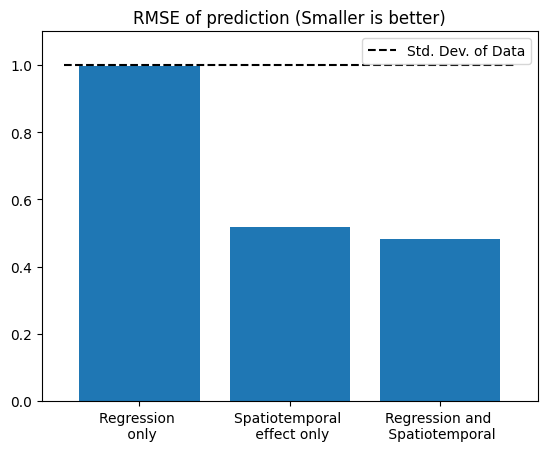

In [ ]:
rmse_plt = [0.9965884685516357, 0.9986969232559204, 0.5167127847671509, 0.4818732738494873]
plt.bar([1, 2, 3], rmse_plt[1:])
plt.plot([0.5, 3.5], [1, 1], 'k--', label="Std. Dev. of Data")
plt.xticks([1, 2, 3], labels=["Regression \n only", "Spatiotemporal \n effect only", "Regression and \n Spatiotemporal"])
plt.title("RMSE of prediction (Smaller is better)")
plt.legend(loc="upper right")
plt.ylim(0, 1.10)
plt.savefig('rmse.png', bbox_inches='tight', dpi=300)

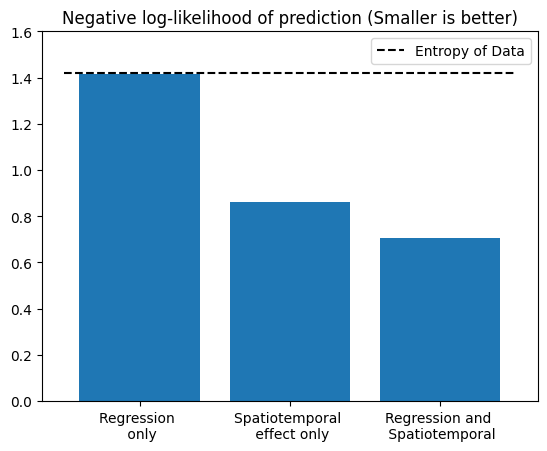

In [58]:
loglike_plt = [-1.4155742091974812, -1.4177230548540594, -0.8637028772433033, -0.7067090186807742]
plt.bar([0, 1, 2, 3][1:], -np.array(loglike_plt[1:]))

plt.plot([0.5, 3.5], np.array([1, 1])*scipy.stats.norm.entropy(0, 1), 'k--', label="Entropy of Data")

plt.xticks([0, 1, 2, 3][1:], labels=["No model", "Regression \n only", "Spatiotemporal \n effect only", "Regression and \n Spatiotemporal"][1:])
plt.title("Negative log-likelihood of prediction (Smaller is better)")
plt.legend(loc="upper right")
plt.ylim(0, 1.6)
plt.savefig('loglike.png', bbox_inches='tight', dpi=300)

In [59]:
print(f"Average Rural RMSE: {np.sqrt(np.power(rmses_rural, 2).mean())}")
print(f"Average Urban RMSE: {np.sqrt(np.power(rmses_urban, 2).mean())}")

Average Rural RMSE: 0.500014066696167
Average Urban RMSE: 0.446030855178833


In [60]:
print(f"Average Rural RMSE: {np.sqrt(np.power(rmses_rural, 2).mean())}")
print(f"Average Urban RMSE: {np.sqrt(np.power(rmses_urban, 2).mean())}")

Average Rural RMSE: 0.500014066696167
Average Urban RMSE: 0.446030855178833


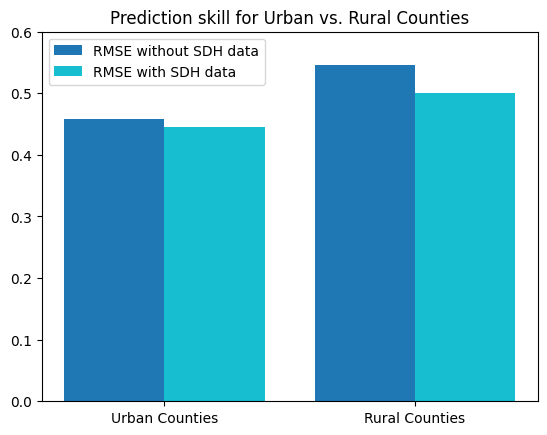

In [61]:
rmse_plt = [ 0.45875027775764465, 0.446030855178833, 0.5452280044555664, 0.500014066696167]
plt.bar([0, 2+0.5], rmse_plt[0:3:2], width=1, label="RMSE without SDH data", color="tab:blue")
plt.bar([1, 3+0.5], rmse_plt[1:4:2], width=1, label="RMSE with SDH data", color="tab:cyan")
plt.xticks([0.5, 3], labels=["Urban Counties", "Rural Counties"])
plt.title("Prediction skill for Urban vs. Rural Counties")
plt.legend()
plt.ylim(0, 0.6)
plt.savefig('rmse_rural.png', bbox_inches='tight', dpi=300)